### 💡 Decision Tree : 의사결정나무
Decision Tree(의사결정나무)는 데이터의 특성을 기준으로 여러 조건을 생성하고, 조건에 따라 데이터를 반복적으로 분할하여 결과를 예측하는 러닝머신 알고리즘이다.

| 구분 | 내용 |
| --- | --- |
| 학습 유형 | 지도 학습 (Supervised Learning) |
| 활용 분야 | 분류 (Classification), 회기 (Regression) |
| 분류 모델 | DecisionTreeClassifier |
| 회기 모델 | DecisionTressRegressor |
| 핵심 원리 | 조건에 따른 재귀적 데이터 분할 |

`KNN`이 가까운 이웃을 예측하는 알고리즘이라면, `Decision Tree`는 **학습된 조건을 따라 이동하면서 결과를 예측하는 알고리즘**이다.

#### 1️⃣ Decision Tree의 구성 요소
| 용어 | 의미 |
| --- | --- |
| `Node` | 데이터의 집합을 나타내는 단위 |
| `Root Node` | 전체 훈련 데이터가 존재하는 시작 노드 |
| `Internal Node` | 추가적인 분할이 발생하는 노드 |
| `Leaf Node` | 더 이상 분할하지 않는 최종 노드 |

`Root Node`의 Depth는 0부터 시작한다.

#### 2️⃣ Decision Tree의 학습 원리

학생의 공부 시간과 출석률을 기준으로 시험 합격 여부를 예측한다고 가정해보자
| 학생 | 공부시간 | 출석률 | 합격 여부 |
| --- | --- | --- | --- |
| A | 1 | 50 | 불합격 |
| B | 2 | 90 | 불합격 |
| C | 3 | 60 | 불합격 |
| D | 4 | 90 | 합격 |
| E | 5 | 60 | 불합격 |
| F | 6 | 90 | 합격 |
| G | 7 | 80 | 합격 |
| H | 8 | 100 | 합격 |

`Feature`는 **공부시간**과 **출석률**이고, `Target`은 **합격 여부**이다.

`Decision Tree`는 **재귀적 분할**(Recursive Splitting)을 하며, 데이터는 한번 분할하는 것이 아니라 분할된 데이터에 대해서도 다시 분할 할 수 있다.

1. 첫번째 분할 &rightarrow; 공부시간이 3.5시간 이하인지 확인한다.
    - True: 불합격 3명
    - False: 합격 4명, 불합격 1명

2. 두번쨰 분할 &rightarrow; 출석률 70%를 기준으로 다시 분할한다.
    - True: 불합격 1명
    - False: 합격 4명

이렇게 같은 종류의 데이터들끼리 모이도록 분할하는 것이 분류 트리의 핵심 원리이다.

여기서 한가지 의문이 생길 수 있다.
- 왜 출석률이 아닌 공부 시간을 먼저 선택했을까?
- 왜 공부시간이 3시간이나 4시간이 아닌 3.5시간을 분할 기준으로 선택했을까?

이러한 분할 조건을 결정하기 위해 **Gini Impurity**, **Entropy** 등의 지표를 사용한다.

In [4]:
# Decision Tree 기본 사용법

# 라이브러리 및 데이터 준비
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

# [공부시간, 출석률%]
X = np.array([
    [1, 50],
    [2, 90],
    [3, 60],
    [4, 90],
    [5, 60],
    [6, 90],
    [7, 80],
    [8, 100]
])

# 0: 불합격, 1: 합격
y = np.array([
    0, 0, 0, 1, 0, 1, 1, 1
])

# 모델 생성 및 학습
model = DecisionTreeClassifier(random_state=42)

# 모델 학습
model.fit(X, y)

# 새로운 데이터 생성
new_X = np.array([[6, 85]])

# 모델 예측
y_pred = model.predict(new_X)
print(y_pred)

[1]


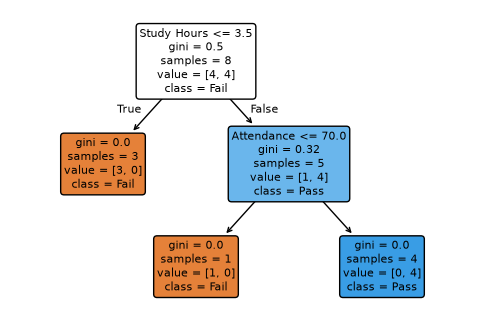

In [ ]:
# Decision Tree 시각화

# Study Hours <= 3.5 : 해당 노드의 분할 조건
# gini : 해당 노드의 불순도
# samples : 해당 노드에 포함된 데이터 개수
# value : 클래스별 데이터 개수 또는 비율
# class : 해당 노드의 예측 클래스

plt.figure(figsize=(6, 4))

plot_tree(
    model,
    feature_names=["Study Hours", "Attendance"], # Feature 이름
    class_names=["Fail", "Pass"], # 분류 클래스 이름
    filled=True, # 클래스와 순서에 따라 노드 색상 표시
    rounded=True, # 노드의 모서리 둥글게
    fontsize=8 # 글자 크기
)

plt.show()

In [10]:
# 트리 구조 확인해보기
# 트리의 최대 깊이
print(model.get_depth())

# Leaf Node 개수
print(model.get_n_leaves())

# 전체 Node 개수
print(model.tree_.node_count)

2
3
5


### 3️⃣ Decision Tree의 장단점

1. 장점
- 예측 원리를 이해하기 쉽다.
- 모델을 시각화 할 수 있다.
- 일반적으로 스케일링이 필요없다.
- 비선형 관계도 학습할 수 있다.
- 분류와 회기 모두 가능하다.

2. 단점
- 과대적합이 발생하기 쉽다.
- 데이터 변화에 민감하다.
- 트리가 깊어지면 해석하기 어렵다.
- 전체적으로 최적의 트리를 보장하지 않는다.
- 기본 회귀 트리는 외삽에 취약하다.

---
#### 실습문제

In [11]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

# 운동 경력(개월), 주간 운동 횟수
X = np.array([
    [1, 1],
    [2, 2],
    [3, 3],
    [4, 2],
    [6, 3],
    [8, 4],
    [12, 5],
    [18, 6],
    [24, 5],
    [36, 6]
])

# 0: 초보자, 1: 숙련자
y = np.array([
    0, 0, 0, 0, 0,
    1, 1, 1, 1, 1
])

# 1. DecisionTreeClassifier 모델 생성
#    random_state=42
model = DecisionTreeClassifier(random_state=42)

# 2. 모델 학습
model.fit(X, y)

# 3. 운동 경력 10개월, 주간 운동 횟수 4회인
#    회원의 숙련도 예측
X_new = np.array([[10, 4]])
y_pred = model.predict(X_new)
print(y_pred)

# 4. 아래 세 회원의 숙련도 한 번에 예측
#    운동 경력 2개월, 주간 운동 횟수 2회
#    운동 경력 7개월, 주간 운동 횟수 3회
#    운동 경력 20개월, 주간 운동 횟수 5회
X_new_batch = np.array([
    [2, 2],
    [7, 3],
    [20, 5]
])
y_pred_batch = model.predict(X_new_batch)
print(y_pred_batch)

[1]
[0 0 1]


1
2
3


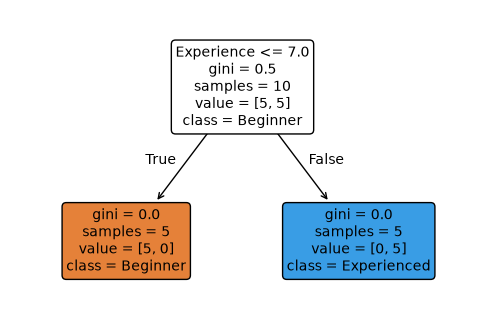

In [ ]:
# 5. plot_tree()를 이용하여 트리 시각화
#    feature_names: Experience, Frequency
#    class_names: Beginner, Experienced
#    filled=True
#    rounded=True
plt.figure(figsize=(6, 4))

plot_tree(
    model,
    feature_names=["Experience", "Frequency"],
    class_names=["Beginner", "Experienced"],
    filled=True,
    rounded=True,
    fontsize=10
)

# 6. 트리의 최대 깊이 출력
print(model.get_depth())

# 7. Leaf Node 개수 출력
print(model.get_n_leaves())

# 8. 전체 Node 개수 출력
print(model.tree_.node_count)

# 9. Root Node의 분할 조건 확인
# Experience <= 7.0

# 10. 3번에서 예측한 회원이 어떤 조건을 거쳐
#     Leaf Node에 도달했는지 설명
# 운동 경력이 10개월이므로 Experience <= 7.0 조건을
# 만족하지 않아 False 방향으로 이동한다.
# 오른쪽 Leaf Node에 도달하여 숙련자(1)로 예측한다.